# 05 · H5: Has labour's share fallen more where intangible, software-heavy capital is concentrated?

**H5.** Industries with higher pre-2008 intellectual-property (software, R&D) intensity show larger declines in labour share, and sectors with higher AI use show weaker labour-share change after 2022.

*SET-III argument tested:* §5.2–5.3, which warn of an underclass excluded from AI-generated wealth.
*Brynjolfsson–McAfee anchor:* the spread and the falling labour share (*Second Machine Age* Ch. 9; Karabarbounis & Neiman 2014), and the Turing Trap's shift of bargaining power to capital owners.

Labour share = compensation of employees ÷ value added (BEA). IP intensity is measured in 1997–2007, before the period of interest, so that later labour-share changes cannot cause it.

In [1]:
from setiii_common import *
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
set_style()
ind = pd.read_csv(DATA_FIN / "industry_panel.csv", dtype={"ind": str})
ind = ind[ind["year"] >= 1997].dropna(subset=["labor_share"]).copy()
ind["trend"] = ind["year"] - 1997
ind["ipz"] = ind["ind"].map(zscore(ind.drop_duplicates("ind").set_index("ind")["ip_int_pre"]))
ind["ls_pct"] = 100 * ind["labor_share"]
fred = pd.read_csv(DATA_INT / "fred.csv", parse_dates=["date"])
print(ind["ind"].nunique(), "industries,", ind["year"].min(), "-", ind["year"].max())

63 industries, 1997 - 2025


## Figure 6. Labour share: aggregate trend and industry divergence

Saved figure fig6_labor_share


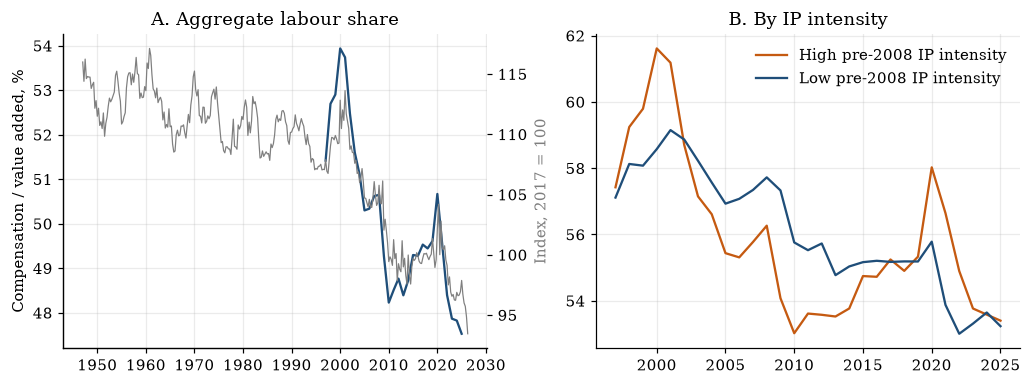

In [2]:
agg = ind.groupby("year").apply(lambda d: 100 * d["comp"].sum() / d["va"].sum(), include_groups=False)
hi = ind[ind["ipz"] > ind.drop_duplicates("ind")["ipz"].median()]
lo = ind[ind["ipz"] <= ind.drop_duplicates("ind")["ipz"].median()]
grp = lambda d: d.groupby("year").apply(lambda x: 100 * x["comp"].sum() / x["va"].sum(), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax = axes[0]
ax.plot(agg.index, agg.values, color=PALETTE["main"], label="All industries (BEA)")
ls = fred[fred["series_id"] == "PRS85006173"].set_index("date")["value"]
if len(ls):
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(ls.index.year + (ls.index.month - 1) / 12, ls.values, color=PALETTE["grey"], lw=0.8, label="Nonfarm business index (FRED)")
    ax2.set_ylabel("Index, 2017 = 100", color=PALETTE["grey"])
ax.set_ylabel("Compensation / value added, %"); ax.set_title("A. Aggregate labour share")
ax = axes[1]
ax.plot(grp(hi).index, grp(hi).values, color=PALETTE["alt"], label="High pre-2008 IP intensity")
ax.plot(grp(lo).index, grp(lo).values, color=PALETTE["main"], label="Low pre-2008 IP intensity")
ax.set_title("B. By IP intensity"); ax.legend()
fig.tight_layout(); save_fig(fig, "fig6_labor_share"); plt.show()

## Table 5. Labour share on IP intensity × trend

In [3]:
rows = []
specs = {
    "(1) Trend × IP intensity": ("ls_pct ~ ipz_trend + C(ind) + C(year)", None),
    "(2) VA-weighted": ("ls_pct ~ ipz_trend + C(ind) + C(year)", "va"),
    "(3) Post-2022 × IP intensity": ("ls_pct ~ ipz_trend + ipz_post22 + C(ind) + C(year)", None),
}
ind["ipz_trend"] = ind["ipz"] * ind["trend"]
ind["ipz_post22"] = ind["ipz"] * (ind["year"] >= 2023)
fits = {}
for lab, (f, w) in specs.items():
    r = fe_ols(ind, f, "ind", w)
    fits[lab] = r
    rows.append(coef_table(r, ("ipz_",), label=lab))
t5 = pd.concat(rows); t5["sig"] = t5["p"].map(stars)
save_table(t5.set_index("model", append=True), "table5_h5_labor_share",
           "Labour share (pp) on pre-2008 IP intensity (SD) × trend; industry and year FE; SEs clustered by industry")
t5.round(4)

Saved table table5_h5_labor_share


,model,coef,se,p,ci_low,ci_high,n_obs,sig
ipz_trend,(1) Trend × IP intensity,-0.0554,0.0809,0.4937,-0.2139,0.1032,1798,
ipz_trend,(2) VA-weighted,-0.0187,0.0484,0.6983,-0.1135,0.0760,1798,
ipz_trend,(3) Post-2022 × IP intensity,-0.0702,0.0995,0.4809,-0.2653,0.1249,1798,
ipz_post22,(3) Post-2022 × IP intensity,0.7699,1.0529,0.4647,-1.2938,2.8336,1798,


## Wild cluster bootstrap for specification (1)

About 60–70 industries is a modest number of clusters. The interaction is re-tested with a wild cluster bootstrap (Rademacher weights, null imposed), after partialling out the two sets of fixed effects.

In [4]:
def wild_cluster_p(df, y, x, cluster, B=9999, seed=7):
    d = df.dropna(subset=[y, x]).copy()
    ry = smf.ols(f"{y} ~ C(ind) + C(year)", d).fit().resid
    rx = smf.ols(f"{x} ~ C(ind) + C(year)", d).fit().resid
    g = pd.factorize(d[cluster])[0]; G = g.max() + 1
    def tstat(yv):
        b = (rx * yv).sum() / (rx**2).sum()
        e = yv - b * rx
        s = np.bincount(g, weights=rx * e, minlength=G)
        se = np.sqrt((s**2).sum()) / (rx**2).sum() * np.sqrt(G / (G - 1))
        return b / se
    t0 = tstat(ry.values)
    rng = np.random.default_rng(seed)
    u = ry.values                     # residuals under H0: beta = 0
    tb = np.array([tstat(u * rng.choice([-1, 1], G)[g]) for _ in range(B)])
    return float(t0), float((np.abs(tb) >= abs(t0)).mean())

t_obs, p_wild = wild_cluster_p(ind, "ls_pct", "ipz_trend", "ind")
print(f"t = {t_obs:.2f}, wild-cluster bootstrap p = {p_wild:.4f}")

t = -0.70, wild-cluster bootstrap p = 0.5124


## Figure 7. Long difference: change in labour share vs IP intensity

Saved figure fig7_long_difference


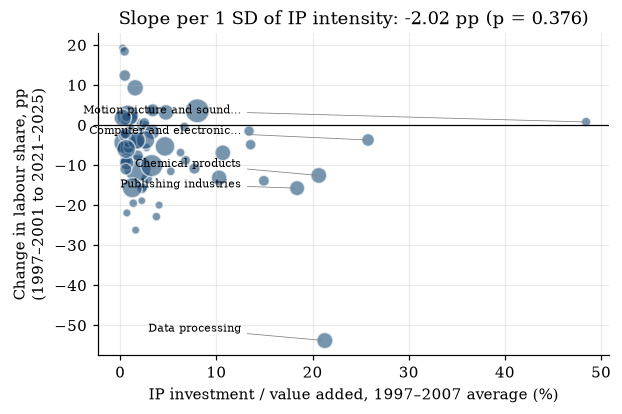

In [5]:
early = ind[ind["year"].between(1997, 2001)].groupby("ind")["ls_pct"].mean()
late_years = (ind["year"].max() - 4, ind["year"].max())
late = ind[ind["year"].between(*late_years)].groupby("ind")["ls_pct"].mean()
ld = pd.DataFrame({"d_ls": late - early}).join(ind.drop_duplicates("ind").set_index("ind")[["name", "ip_int_pre", "ipz"]])
ld["va_late"] = ind[ind["year"] == ind["year"].max()].set_index("ind")["va"]
ld = ld.dropna(subset=["d_ls", "ip_int_pre"])
rl = smf.wls("d_ls ~ ipz", ld, weights=np.ones(len(ld))).fit(cov_type="HC1")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.scatter(100 * ld["ip_int_pre"], ld["d_ls"], s=20 + 300 * ld["va_late"] / ld["va_late"].max(),
           color=PALETTE["main"], alpha=0.6, edgecolor="white")
# Label the five most IP-intensive industries; stack labels so they never overlap.
lab = ld.nlargest(5, "ip_int_pre").sort_values("d_ls", ascending=False)
yr = ld["d_ls"].max() - ld["d_ls"].min()
gap, prev = 0.07 * yr, np.inf
xs = 100 * lab["ip_int_pre"]
x_text = xs.min() - 0.12 * (100 * ld["ip_int_pre"].max())
for nm, r_ in lab.iterrows():
    y_text = min(r_["d_ls"] + 0.04 * yr, prev - gap)
    prev = y_text
    ax.annotate(short_name(r_["name"]), (100 * r_["ip_int_pre"], r_["d_ls"]), xytext=(x_text, y_text),
                ha="right", va="center", fontsize=7,
                arrowprops=dict(arrowstyle="-", color=PALETTE["grey"], lw=0.5))
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("IP investment / value added, 1997–2007 average (%)")
ax.set_ylabel(f"Change in labour share, pp\n(1997–2001 to {late_years[0]}–{late_years[1]})")
ax.set_title(f"Slope per 1 SD of IP intensity: {rl.params['ipz']:.2f} pp ({fmt_p(rl.pvalues['ipz'])})")
save_fig(fig, "fig7_long_difference"); plt.show()

## AI use by sector after 2022 (descriptive)

In [6]:
ai_res = None
if ind["ai_use_pct"].notna().any():
    s = ind.dropna(subset=["ai_use_pct"])
    yrs = sorted(s["year"].unique())
    if 2022 in yrs and max(yrs) > 2022:
        sec = s.groupby(["sector2", "year"]).apply(lambda d: 100 * d["comp"].sum() / d["va"].sum(), include_groups=False).unstack()
        dd = pd.DataFrame({"d_ls_post": sec[max(yrs)] - sec[2022],
                           "ai_use_pct": s.groupby("sector2")["ai_use_pct"].first()}).dropna()
        rho = dd.corr(method="spearman").iloc[0, 1]
        ai_res = {"n_sectors": len(dd), "spearman": round(float(rho), 3)}
        print(dd.sort_values("ai_use_pct", ascending=False).round(2)); print(ai_res)
else:
    print("No AI-use data; skipped.")

         d_ls_post  ai_use_pct
sector2                       
51           -1.57       41.20
54           -1.29       37.66
52           -7.39       34.05
61           -0.87       32.50
55           -0.02       30.89
53           -0.46       26.24
62           -1.88       22.35
56           -1.51       18.66
71            0.78       18.53
42           -3.32       16.90
31            1.22       16.81
44           -0.37       14.56
22            0.93       14.54
23            1.31       11.87
81            0.38       11.00
21            5.92        9.04
48            3.31        9.02
72           -0.99        8.58
11            7.75        7.62
{'n_sectors': 19, 'spearman': -0.689}


## Numbers for the paper

In [7]:
r1 = fits["(1) Trend × IP intensity"]
res = {
    "n_industries": int(ind["ind"].nunique()), "years": [int(ind["year"].min()), int(ind["year"].max())],
    "aggregate_ls_first_last": [round(float(agg.iloc[0]), 2), round(float(agg.iloc[-1]), 2)],
    "ipz_trend": {"coef": round(float(r1.params["ipz_trend"]), 4), "p": float(r1.pvalues["ipz_trend"]),
                  "wild_p": p_wild},
    "ipz_trend_over_period_pp": round(float(r1.params["ipz_trend"]) * float(ind["trend"].max()), 2),
    "post22": {"coef": round(float(fits["(3) Post-2022 × IP intensity"].params["ipz_post22"]), 4),
               "p": float(fits["(3) Post-2022 × IP intensity"].pvalues["ipz_post22"])},
    "long_difference_slope_pp": round(float(rl.params["ipz"]), 3), "long_difference_p": float(rl.pvalues["ipz"]),
    "ai_use": ai_res,
}
res["verdict"] = "supported" if (r1.params["ipz_trend"] < 0 and p_wild < 0.05) else "not supported"
(DATA_FIN / "results_h5.json").write_text(json.dumps(res, indent=2, default=str))
print(json.dumps(res, indent=2, default=str))

{
  "n_industries": 63,
  "years": [
    1997,
    2025
  ],
  "aggregate_ls_first_last": [
    51.42,
    47.53
  ],
  "ipz_trend": {
    "coef": -0.0554,
    "p": 0.49365226457667644,
    "wild_p": 0.5123512351235123
  },
  "ipz_trend_over_period_pp": -1.55,
  "post22": {
    "coef": 0.7699,
    "p": 0.46466296933919016
  },
  "long_difference_slope_pp": -2.019,
  "long_difference_p": 0.3756181107332719,
  "ai_use": {
    "n_sectors": 19,
    "spearman": -0.689
  },
  "verdict": "not supported"
}
